In [260]:
from astroquery.gaia import Gaia
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.coordinates import Angle
from scipy.optimize import curve_fit
from astropy.coordinates import SkyCoord

In [262]:
# zvezde spektralnog tipa O (Teff >= 30,000 K)
# uzimamo samo 2000

o_query = """
SELECT TOP 3000
    g.source_id, 
    g.ra, 
    g.dec, 
    g.parallax, 
    g.parallax_over_error, 
    g.pmra, 
    g.pmdec, 
    g.phot_g_mean_mag, 
    g.bp_rp,
    a.teff_gspphot
FROM gaiadr3.gaia_source AS g
JOIN gaiadr3.astrophysical_parameters AS a ON g.source_id = a.source_id
WHERE a.teff_gspphot >= 30000
  AND g.parallax > 0
  AND g.parallax_over_error > 5
"""

job_o = Gaia.launch_job_async(o_query)
df_o = job_o.get_results().to_pandas()
df_o.to_csv("o_stars.csv", index=False)

INFO: Query finished. [astroquery.utils.tap.core]


In [263]:
# učitavam podatke za O: ra, dec i parallax
df_o = pd.read_csv("o_stars.csv")
o_data = df_o[["ra", "dec", "parallax"]]

In [266]:
# učitavamo celi katalog - Vizier ima svoj row limit
Vizier.ROW_LIMIT = -1

# globularna jata
globular_result = Vizier.get_catalogs("VII/202")
df_globular = globular_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_globular_clean = df_globular[["ID", "RAJ2000", "DEJ2000"]]
df_globular_clean.to_csv("globular_clusters_harris.csv", index=False)

# otvorena jata
open_result = Vizier.get_catalogs("B/ocl")
df_open = open_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_open_clean = df_open[["RAJ2000", "DEJ2000", "Dist"]]
df_open_clean.to_csv("open_clusters_dias.csv", index=False)

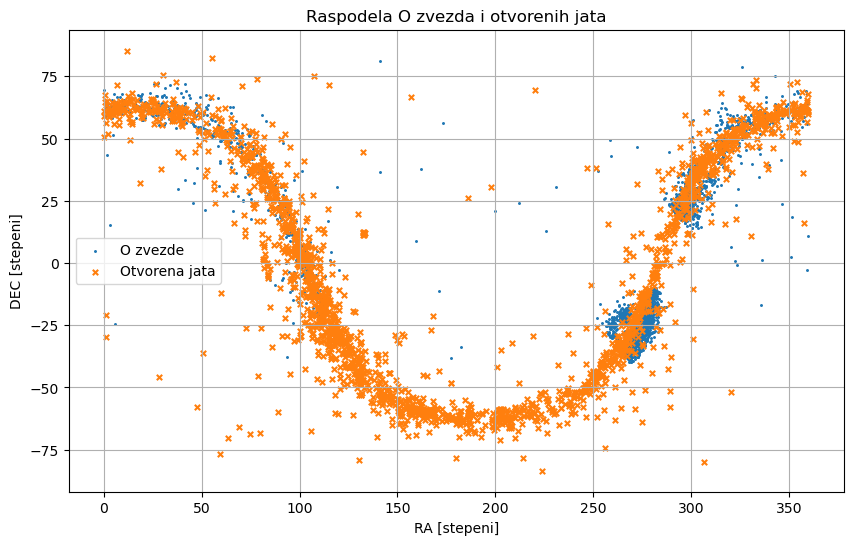

In [268]:
#Ovaj deo koda koristimo da bismo pretvorili koordinate otvorenih zvezdanih jata u stepene, kako bismo mogli pravilno da ih prikažemo na grafiku
ra_open = Angle(df_open_clean["RAJ2000"].astype(str).tolist(), unit=u.hourangle).degree
dec_open = Angle(df_open_clean["DEJ2000"].astype(str).tolist(), unit=u.deg).degree
#crtamo grafik sa O zvezdama i otvorenim jatima
plt.figure(figsize=(10, 6))
plt.scatter(df_o["ra"], df_o["dec"], s=5, marker=".", label="O zvezde")
plt.scatter(ra_open, dec_open, s=15, marker="x", label="Otvorena jata")
plt.xlabel("RA [stepeni]")
plt.ylabel("DEC [stepeni]")
plt.title("Raspodela O zvezda i otvorenih jata")
plt.legend()
plt.grid()
plt.show()


Sa prethodnog grafika na kom vidimo prikaz raspodele otvorenih jata kao i O zvezda vidimo da obe raspodele prate pojas koji odgovara projekciji ravnu Mlečnog puta, naravno uz bitnu napomenu da primećujemo manji broj O zvezda u odnosu na Otvorena jata kao i pojedine oblasti veće koncentracije O zvezda u ravni Mlečnog puta.

In [271]:
#Udaljenost do zvezde računa se pomoću paralakse: d=1/p (paralaksa u lucnim sekundama)
df_o["distance"] = 1000 / df_o["parallax"]
#print(df_o[["parallax", "distance"]].head()) #provera

Udaljenost O zvezda određujemo na osnovu njihove paralakse iz podataka pomoću formule $d=1000/p$ pri čemu dobijamo zapravo udaljenost u parsecima.

RA pola = 194.54395361866938
DEC pola = 28.41540341939787


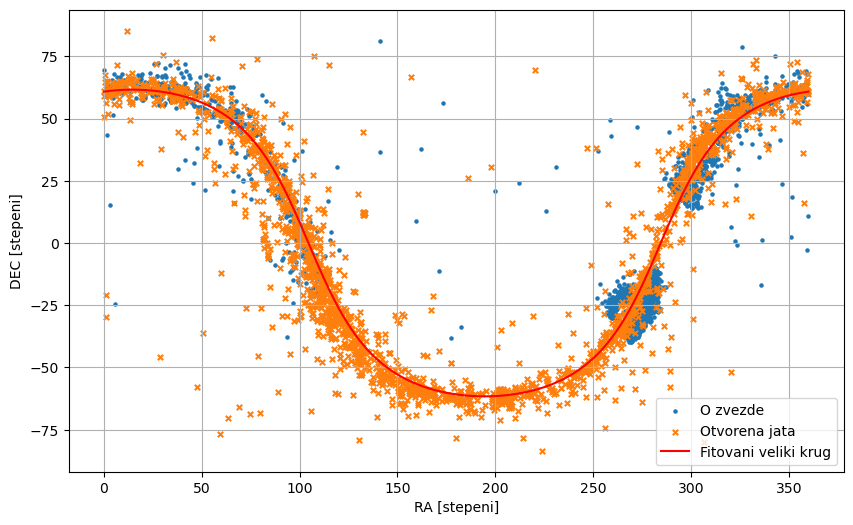

In [274]:
#spajamo podatke 
ra = np.concatenate([df_o["ra"], ra_open])
dec = np.concatenate([df_o["dec"], dec_open])
#pravimo funkciju
def veliki_krug(ra, alpha_w, i):
    return np.degrees(np.arctan(np.sin(np.radians(ra - alpha_w)) * np.tan(np.radians(i))))

#fitujemo funkciju 
parametri, _ = curve_fit(veliki_krug, ra, dec, p0=[280, 60])
#uimamo fitovane parametre 
alpha_w, i = parametri
#računamo koordinate severnog galaktičkog pola 
alpha_png = (alpha_w - 90) % 360
delta_png = 90 - i
print("RA pola =", alpha_png)
print("DEC pola =", delta_png)
#fitovane koordinate
ra_fit = np.linspace(0, 360, 500)
dec_fit = veliki_krug(ra_fit, alpha_w, i)
#crtamo grafik sa fitovanom kruvom
plt.figure(figsize=(10, 6))
plt.scatter(df_o["ra"], df_o["dec"], s=5, label="O zvezde")
plt.scatter(ra_open, dec_open, s=15, marker="x", label="Otvorena jata")
plt.plot(ra_fit, dec_fit, color="red", label="Fitovani veliki krug")
plt.xlabel("RA [stepeni]")
plt.ylabel("DEC [stepeni]")
plt.title("")
plt.legend()
plt.grid()
plt.show()
#NAPOMENA NISAM UPOREDIO PODATKE

In [276]:
#Poređenje sa vrednostima za J2000
alpha_ref = 15 * (18 + 51/60 + 26/3600)
i_ref = 62.87
#razlike fitovanih i datih parametara
print("Razlika alpha_w =", abs(alpha_w - alpha_ref))
print("Razlika i =", abs(i - i_ref))

Razlika alpha_w = 1.6856202853360287
Razlika i = 1.2854034193978663


Dobijena razlika iznosi za rektascenziju 1.69$\degree$ i za deklinaciju 1.28$\degree$

Pomoću curve fit funkcije određujemo fitovane parametre velikog kruga koju opisuje raspodelu O zvezda i otvorenih jata. Takođe smo izračunali koordinate severonog galaktičkog pola $\alpha_{PNG}$ i $\beta_{PNG}$. Odstupanja zasigurno postoje jer kao što vidimo nisu svi objekti rapoređeni u galaktičkoj ravni.

In [281]:
#ekvatorijalne koordinate globularnih jata 
koordinate = SkyCoord(ra=df_globular_clean["RAJ2000"].astype(str).tolist(),dec=df_globular_clean["DEJ2000"].astype(str).tolist(),unit=(u.hourangle, u.deg),frame="icrs")
#pretvaramo u galaktičke koordinate
df_globular_clean["l"] = koordinate.galactic.l.degree
df_globular_clean["b"] = koordinate.galactic.b.degree

Pomocu Skycoord funkcije izvrsena je transformacija ekvatorijalnih koordinata u galaktičke koordina te za globularna jata 

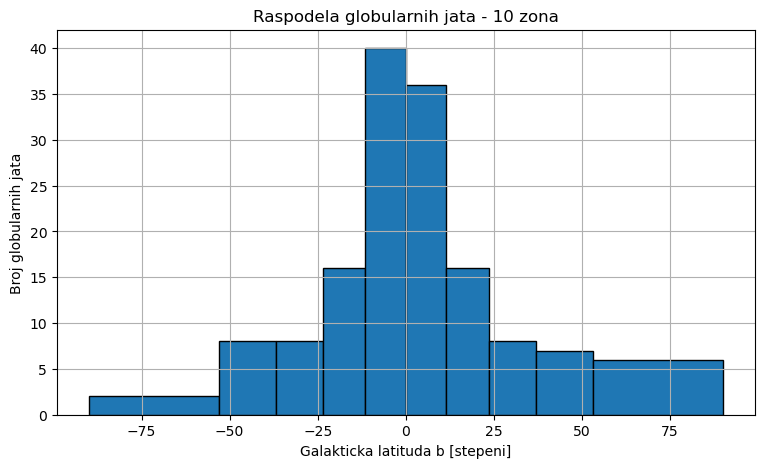

In [284]:
#galaktičke latitude jata
b = df_globular_clean["b"].dropna()
#granice zona
gr10 = np.degrees(np.arcsin(np.linspace(-1, 1, 11)))
#broj jata
br10, _ = np.histogram(b, bins=gr10)
#histogram
plt.figure(figsize=(9, 5))
plt.hist(b, bins=gr10, edgecolor="black")
plt.xlabel("Galakticka latituda b [stepeni]")
plt.ylabel("Broj globularnih jata")
plt.title("Raspodela globularnih jata - 10 zona")
plt.grid()
plt.show()

Sa histograma lako se primeti da se većina globularnih jata nalazi oko galaktičkog ekvatora sto je nula stepeni.
Naravno vidimo da je najveća koncentracija između -12 i 12 stepeni i da naglo opada za vece vrednosti.

In [287]:
#centralne latitude 
cen10 = np.degrees(np.arcsin(np.linspace(-0.9, 0.9, 10)))
#b maksimalno
b_max = np.sum(br10 * cen10) / np.sum(br10)
#dobijene vrednosti
print("b_max za 10 zona =", b_max)

b_max za 10 zona = 1.287405326785436


In [289]:
#ponavljamo sve isto za 20 zona
gr20 = np.degrees(np.arcsin(np.linspace(-1, 1, 21)))
br20, _ = np.histogram(b, bins=gr20)
cen20 = np.degrees(np.arcsin(np.linspace(-0.95, 0.95, 20)))
b_max20 = np.sum(br20 * cen20) / np.sum(br20)
print("b_max za 20 zona =", b_max20)

b_max za 20 zona = 1.5349679924830106


Za 10 zona dobijena je vrednost $b_{max}\approx$1.29 dok je za 20 zona dobijena vrednost $b_{max}\approx$1.53. Očekivana vrednost je nula stepeni što u oba slučaja odgovara vrednosti kako su obe dobijene vrednosti jako male. Time zaključujemo da je raspodelja globuralnih jata simetrična u odnosu na galaktički ekvator.

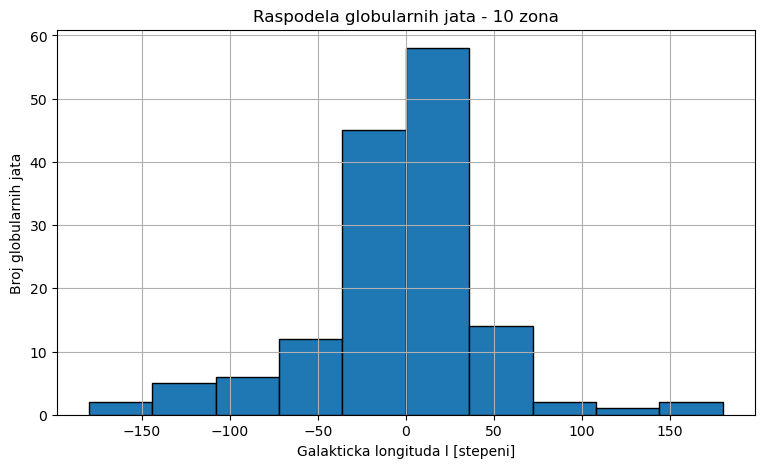

In [292]:
#galaktička longituda
l = df_globular_clean["l"].dropna()
#menjamo interval od -180 do 180
l = (l +180) % 360 - 180
#granice zona 
gr10 = np.linspace(-180, 180, 11)
#broj jata
br10, _ = np.histogram(l, bins=gr10)
#histogram
plt.figure(figsize=(9, 5))
plt.hist(l, bins=gr10, edgecolor="black")
plt.xlabel("Galakticka longituda l [stepeni]")
plt.ylabel("Broj globularnih jata")
plt.title("Raspodela globularnih jata - 10 zona")
plt.grid()
plt.show()

In [295]:
#centralna longituda 
cen10 = (gr10[:-1] + gr10[1:]) / 2
#centar raspodele
l_max10 = np.sum(br10 * cen10) / np.sum(br10)
print("l_max za 10 zona =", l_max10)

l_max za 10 zona = -3.5510204081632653


In [297]:
#ponavljamo sve isto za 20
gr20 = np.linspace(-180, 180, 21)
br20, _ = np.histogram(l, bins=gr20)
cen20 = (gr20[:-1] + gr20[1:]) / 2
l_max20 = np.sum(br20 * cen20) / np.sum(br20)
print("l_max za 20 zona =", l_max20)

l_max za 20 zona = -4.346938775510204


Primećujemo i ovde da su vrednosti približno nula u odnosu na galaktički centar (što je očekivana vrednost), kada uzmemo u obzir informacije  latitude zaključujemo da su globularna jata raspoređena u sfernoj strukturi oko centra mlečnog puta što se slaže sa očekivanjima.

In [300]:
#Koo. centra 10 zona (iz galaktičkog u ekvatorijalni koo.)
centar10 = SkyCoord(l=l_max10*u.deg, b=b_max*u.deg, frame="galactic").icrs
#Koo. centra 20 zona
centar20 = SkyCoord(l=l_max20*u.deg, b=b_max20*u.deg, frame="galactic").icrs
#Rezultati
print("10 zona:")
print("RA =", centar10.ra.degree)
print("DEC =", centar10.dec.degree)
print("20 zona:")
print("RA =", centar20.ra.degree)
print("DEC =", centar20.dec.degree)


10 zona:
RA = 262.9553722819857
DEC = -31.251375658463925
20 zona:
RA = 262.19937686638997
DEC = -31.77961313770637


In [302]:
#Koordinate Sagittarius A
sgr = SkyCoord("17h45m40s", "-29d00m28s", frame="icrs")
#Ugaono rastojanje od Sag A*
print("Odstupanje za 10 zona =", centar10.separation(sgr).degree)
print("Odstupanje za 20 zona =", centar20.separation(sgr).degree)

Odstupanje za 10 zona = 3.740677202378411
Odstupanje za 20 zona = 4.572657072103202


Transformacijom u ekvatorijalni koo sistem dobijene su približne vrednosti $RA$=262.96$\degree$ $DEC$=-31.25$\degree$ za 10 zona i $RA$=262.20$\degree$ $DEC$=-31.78$\degree$ za 20 zona. Poređenje sa koordinatama Sagittariusa A dobili smo vrednosti odstupanja od par stepeni koja iznose za 10 zona :3.74 i z 20 zona :4.57 što je u slkadu sa odstupanjima koja smo već dobili za galaktičku longitudu i latitudu. To smo i očekivali jer smo koristili iste položaje samo u različitom koorinatnom sistemu.